<a href="https://colab.research.google.com/github/munyeshyakajmv1/colab-git-assignment2-JMV/blob/main/Assignment_8_Supervised_Learning_Classification_JMV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Assignment 8: Supervised Learning Classification**
##**Breast Cancer Classification Using Machine Learning**

**Student Name**:Jean Marie Vianney Munyeshyaka

**Course**:Data Analytics & Artificial Intelligence

##**Objective**
The objective of this project is to build and evaluate supervised machine learning classification models capable of predicting whether a breast tumor is malignant or benign. The project includes data preprocessing, exploratory data analysis (EDA), model training, evaluation, interpretation, deployment strategy, and monitoring considerations.

##**IMPORT REQUIRED LIBRARIES**

In [2]:
# ============================================================
# IMPORT REQUIRED LIBRARIES
# ============================================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import load_breast_cancer

# Data preprocessing
from sklearn.model_selection import train_test_split

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')


##**Dataset Selection and Loading**
The Breast Cancer Wisconsin dataset is a widely used classification dataset.

Target Classes:

0 = Malignant

1 = Benign

The dataset contains diagnostic measurements computed from breast cancer images.

In [3]:
# ============================================================
# LOAD THE DATASET
# ============================================================

# Load dataset
cancer = load_breast_cancer()

# Convert to DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add target variable
df["target"] = cancer.target

# Display first rows
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


##**Dataset Inspection**
The following section examines the structure and quality of the dataset before model building.

In [4]:
# Dataset dimensions
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information")
df.info()

Dataset Shape:
(569, 31)

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-n

In [5]:
# Summary statistics
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


**CHECK MISSING VALUES**

In [6]:
# ============================================================
# CHECK MISSING VALUES
# ============================================================

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


**CHECK DUPLICATES**

In [7]:
# ============================================================
# CHECK DUPLICATES
# ============================================================

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


##**Exploratory Data Analysis (EDA)**
EDA helps us understand:

Distribution of classes
Relationships between features
Potential issues affecting model performance

**VISUALIZE CLASS DISTRIBUTION**

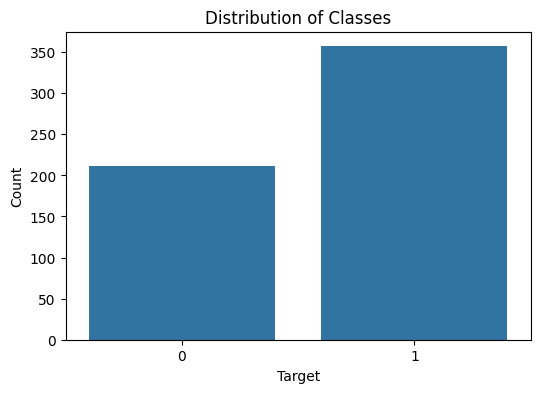

In [8]:
# ============================================================
# VISUALIZE CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(6,4))

sns.countplot(
    x='target',
    data=df
)

plt.title("Distribution of Classes")
plt.xlabel("Target")
plt.ylabel("Count")

plt.show()

 **CORRELATION HEATMAP**

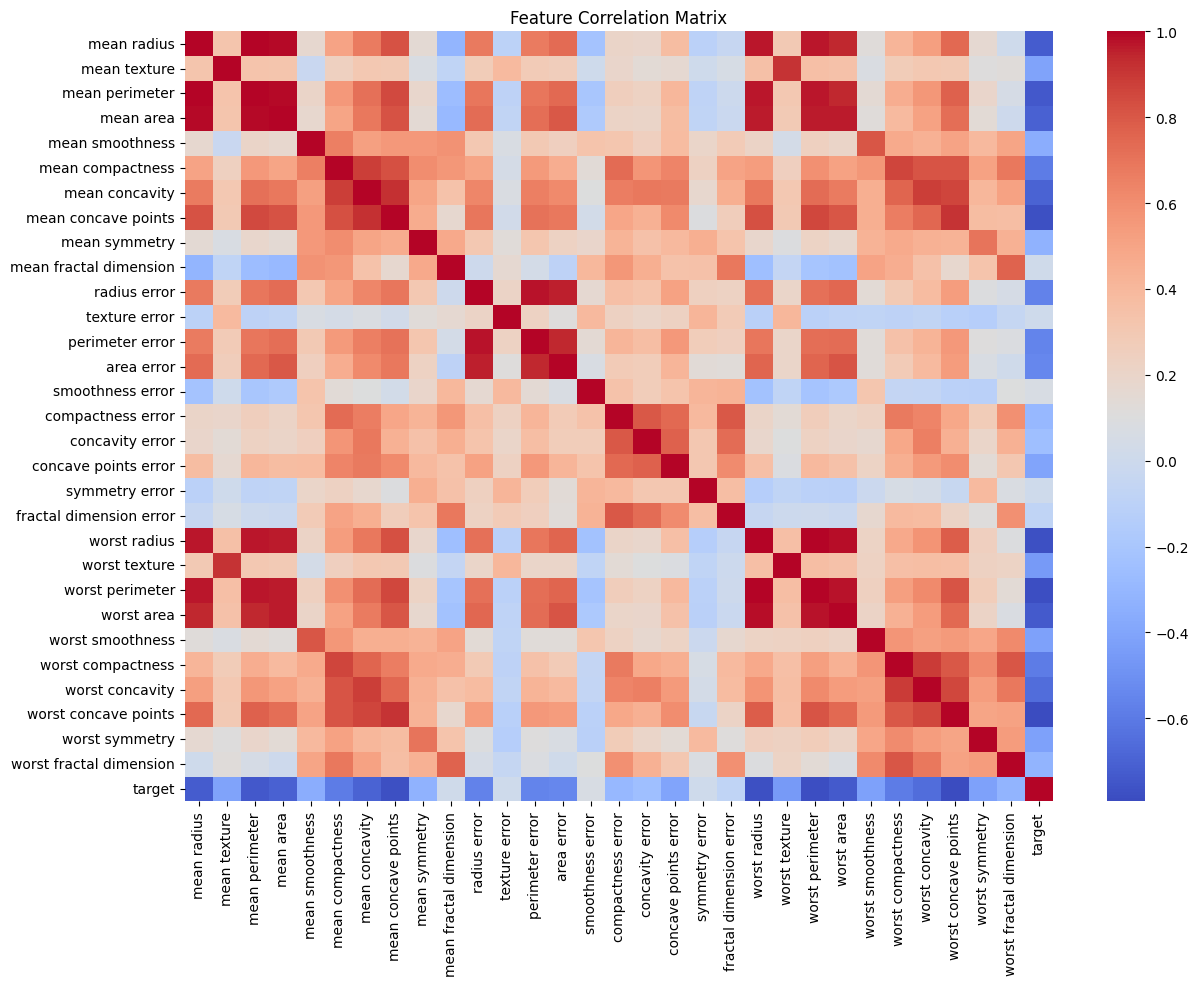

In [9]:
# ============================================================
# CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(14,10))

sns.heatmap(
    df.corr(),
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")

plt.show()

 **VISUALIZE IMPORTANT FEATURES**

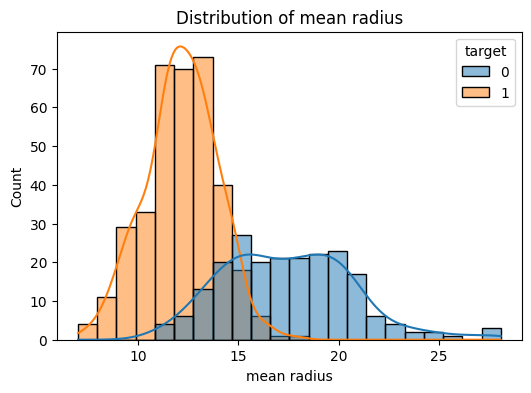

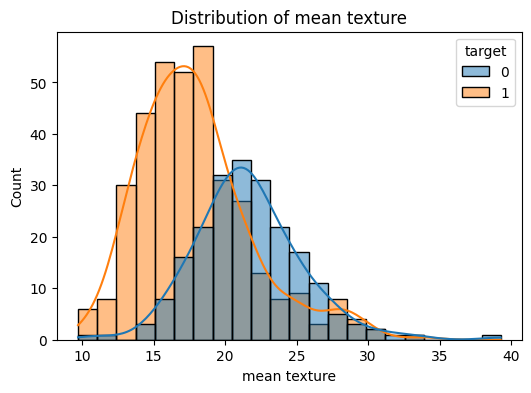

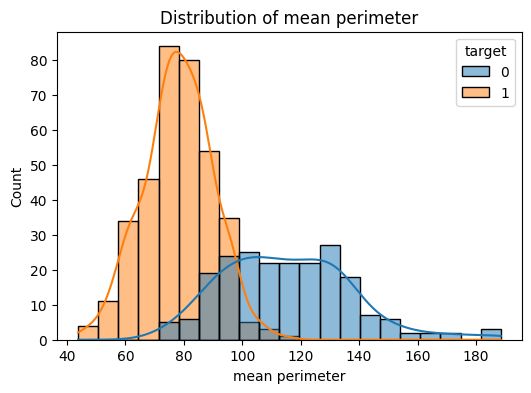

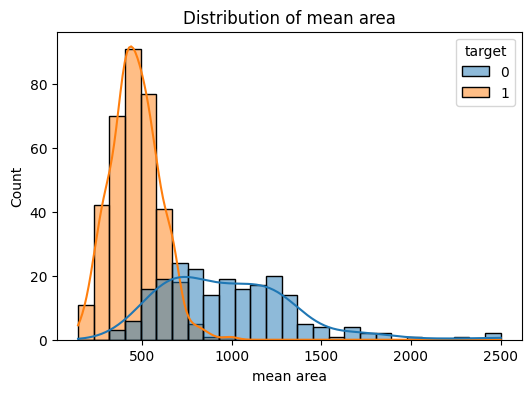

In [10]:
# ============================================================
# VISUALIZE IMPORTANT FEATURES
# ============================================================

selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area'
]

for feature in selected_features:

    plt.figure(figsize=(6,4))

    sns.histplot(
        data=df,
        x=feature,
        hue='target',
        kde=True
    )

    plt.title(f"Distribution of {feature}")

    plt.show()

##**Data Preprocessing**
The target variable is already encoded.

Next, the data will be split into training and testing sets using an 80/20 ratio.

**DEFINE FEATURES AND TARGET**

In [11]:
# ============================================================
# DEFINE FEATURES AND TARGET
# ============================================================

X = df.drop("target", axis=1)

y = df["target"]

**TRAIN TEST SPLIT**

In [12]:
# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (455, 30)
Testing Set: (114, 30)


##**Model 1: Logistic Regression**
Logistic Regression is a baseline classification algorithm commonly used for binary classification problems.

In [13]:
# ============================================================
# TRAIN LOGISTIC REGRESSION
# ============================================================

lr_model = LogisticRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

##**Model 2: Random Forest Classifier**
Random Forest combines multiple decision trees and often delivers higher classification accuracy.

In [14]:
# ============================================================
# TRAIN RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

##**Model Evaluation**
The models are evaluated using:

Accuracy

Precision

Recall

F1 Score

ROC-AUC

**EVALUATION FUNCTION**

In [15]:
# ============================================================
# EVALUATION FUNCTION
# ============================================================

def evaluate_model(y_true, y_pred, model_name):

    print(f"\n{model_name}")
    print("-" * 40)

    print("Accuracy:",
          accuracy_score(y_true, y_pred))

    print("Precision:",
          precision_score(y_true, y_pred))

    print("Recall:",
          recall_score(y_true, y_pred))

    print("F1 Score:",
          f1_score(y_true, y_pred))

In [16]:
evaluate_model(
    y_test,
    lr_predictions,
    "Logistic Regression"
)

evaluate_model(
    y_test,
    rf_predictions,
    "Random Forest"
)


Logistic Regression
----------------------------------------
Accuracy: 0.956140350877193
Precision: 0.9459459459459459
Recall: 0.9859154929577465
F1 Score: 0.9655172413793104

Random Forest
----------------------------------------
Accuracy: 0.9649122807017544
Precision: 0.958904109589041
Recall: 0.9859154929577465
F1 Score: 0.9722222222222222


##**Confusion Matrix Visualization**

**CONFUSION MATRIX - LOGISTIC REGRESSION**

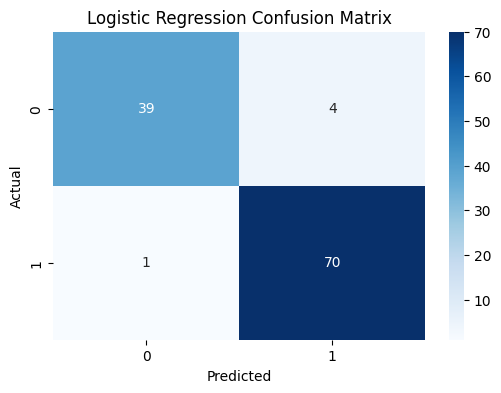

In [17]:
# ============================================================
# CONFUSION MATRIX - LOGISTIC REGRESSION
# ============================================================

cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

**CONFUSION MATRIX - RANDOM FOREST**

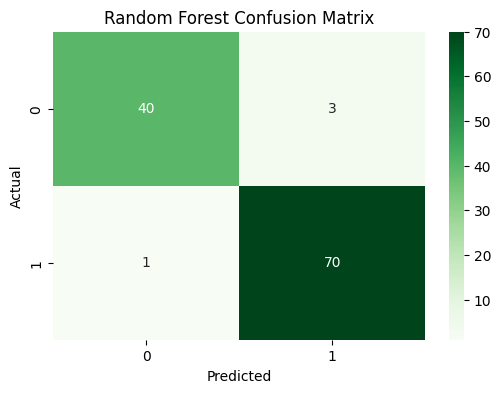

In [18]:
# ============================================================
# CONFUSION MATRIX - RANDOM FOREST
# ============================================================

cm_rf = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

##**ROC Curve Analysis**
ROC curves help evaluate the classifier's ability to distinguish between classes.

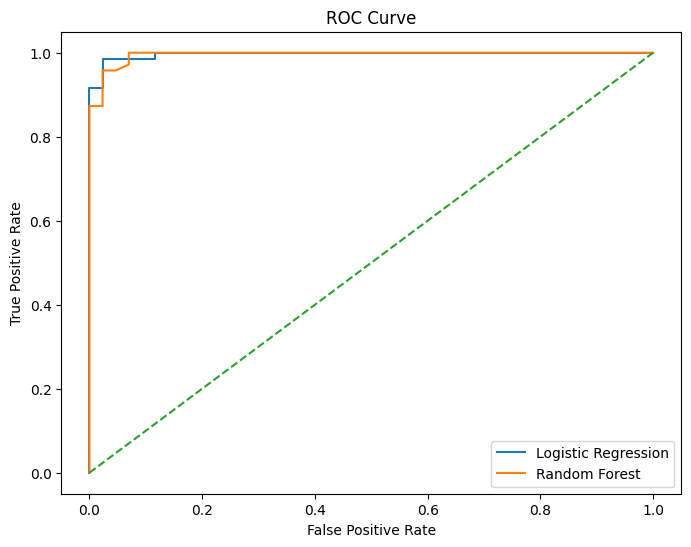

In [19]:
# ============================================================
# ROC CURVE
# ============================================================

lr_probs = lr_model.predict_proba(X_test)[:,1]

rf_probs = rf_model.predict_proba(X_test)[:,1]

lr_fpr, lr_tpr, _ = roc_curve(
    y_test,
    lr_probs
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probs
)

plt.figure(figsize=(8,6))

plt.plot(
    lr_fpr,
    lr_tpr,
    label="Logistic Regression"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label="Random Forest"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.show()

##**Model Interpretation**
Compare the metrics generated above.

The model with:

Higher Accuracy
Higher Precision
Higher Recall
Higher F1 Score
Better ROC performance
will be selected as the best-performing classifier.

Both classification models performed exceptionally well in predicting whether tumors were malignant or benign. The Logistic Regression model achieved an accuracy of 95.61%, a precision of 94.59%, a recall of 98.59%, and an F1-score of 96.55%. The confusion matrix shows that the model correctly classified 39 malignant cases and 70 benign cases, while making 4 false positive predictions and 1 false negative prediction.

The Random Forest model slightly outperformed Logistic Regression across most evaluation metrics. It achieved an accuracy of 96.49%, a precision of 95.89%, a recall of 98.59%, and an F1-score of 97.22%. Its confusion matrix indicates 40 correctly classified malignant cases and 70 correctly classified benign cases, with only 3 false positives and 1 false negative. This reduction in classification errors contributed to its superior overall performance.

The ROC curves for both models are very close to the top-left corner of the graph, demonstrating excellent classification capability and strong separation between the two classes. Both models achieved very high true positive rates while maintaining low false positive rates, indicating reliable and robust predictions.

Based on the evaluation metrics, confusion matrices, and ROC curve analysis, the Random Forest classifier is the preferred model for this dataset. It achieved the highest accuracy, precision, and F1-score while maintaining the same high recall as Logistic Regression. The lower number of false positives also suggests that Random Forest is slightly better at distinguishing between malignant and benign tumors, making it the most effective model for this classification task.

##**Deployment Strategy**
The best model can be deployed as a REST API using Flask or FastAPI.

Deployment Steps:

Save the trained model using Pickle.

Create an API endpoint.

Accept incoming feature values.

Generate predictions.

Return predictions to users.

Host on Azure, AWS, or Google Cloud.

##**Monitoring and Maintenance**
**Potential Challenges**:

Data drift

Concept drift

Missing values in incoming data

Increased prediction latency

**Monitoring Strategies**:

Track prediction accuracy

Monitor precision, recall, and F1-score

Retrain model periodically

Log real-time predictions

Set alerts for performance degradation

##**Conclusion**

This project successfully applied supervised machine learning techniques to classify breast cancer tumors as malignant or benign. Both Logistic Regression and Random Forest achieved excellent results, with accuracies above 95%. However, Random Forest performed slightly better, achieving 96.49% accuracy, 95.89% precision, 98.59% recall, and an F1-score of 97.22%. The confusion matrix and ROC curve confirmed its strong ability to distinguish between classes with very few misclassifications. Based on these results, Random Forest was selected as the best-performing model and is recommended for deployment in a real-world breast cancer classification system.